# LQR: bringing a double integrator to rest

This notebook solves a finite-horizon **linear quadratic regulator** (LQR) problem with
`diffilqrax.lqr.solve_lqr`. It then checks the solution against the KKT optimality conditions
and against the parallel solver `diffilqrax.plqr.solve_plqr`.

**The problem.** The state is a position and velocity, $x = (p, v)$, and the input $u$ is an
acceleration. The discretised dynamics with time step $\delta t$ are

$$
x_{t+1} = A x_t + B u_t, \qquad
A = \begin{pmatrix} 1 & \delta t \\ 0 & 1 \end{pmatrix}, \quad
B = \begin{pmatrix} \tfrac12 \delta t^2 \\ \delta t \end{pmatrix}.
$$

We want to bring the state to rest at the origin using little control effort, so we minimise

$$
J = \tfrac12 x_T^\top Q_f x_T + \sum_{t=0}^{T-1} \tfrac12 \left( x_t^\top Q x_t + u_t^\top R u_t \right).
$$

In [1]:
from functools import partial

import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt

from diffilqrax.lqr import solve_lqr, kkt
from diffilqrax.plqr import solve_plqr
from diffilqrax.typs import LQR, LQRParams, ModelDims

jax.config.update("jax_enable_x64", True)

## Setting up the problem

diffilqrax uses the general time-varying LQR cost

$$
\ell_t(x, u) = \tfrac12 x^\top Q_t x + q_t^\top x + \tfrac12 u^\top R_t u + r_t^\top u + x^\top S_t u,
\qquad x_{t+1} = A_t x_t + B_t u_t + a_t ,
$$

with terminal cost $\tfrac12 x^\top Q_f x + q_f^\top x$. Every time-varying term is stacked along
a leading time axis of length $T$. This problem is time-invariant, so we tile each matrix
$T$ times.

In [2]:
dims = ModelDims(n=2, m=1, horizon=100, dt=0.1)
T, n, m = dims.horizon, dims.n, dims.m

A = jnp.array([[1.0, dims.dt], [0.0, 1.0]])
B = jnp.array([[0.5 * dims.dt**2], [dims.dt]])

span_mat = partial(jnp.tile, reps=(T, 1, 1))  # (n, k) -> (T, n, k)
span_vec = partial(jnp.tile, reps=(T, 1))     # (n,)   -> (T, n)

lqr = LQR(
    A=span_mat(A),
    B=span_mat(B),
    a=span_vec(jnp.zeros(n)),
    Q=span_mat(jnp.eye(n)),
    q=span_vec(jnp.zeros(n)),
    R=span_mat(jnp.eye(m)),
    r=span_vec(jnp.zeros(m)),
    S=span_mat(jnp.zeros((n, m))),
    Qf=jnp.eye(n),
    qf=jnp.zeros(n),
)

x0 = jr.normal(jr.PRNGKey(0), (n,))
params = LQRParams(x0=x0, lqr=lqr)
print("initial state:", x0)

initial state: [ 1.81608667 -0.75488484]


## Solving

`solve_lqr` runs a Riccati backward pass and then a forward rollout. It returns the optimal states
$x_{0:T}$, the inputs $u_{0:T-1}$ and the costates (Lagrange multipliers) $\lambda_{0:T}$.

In [3]:
Xs, Us, lambdas = solve_lqr(params)
print(Xs.shape, Us.shape, lambdas.shape)

(101, 2) (100, 1) (101, 2)


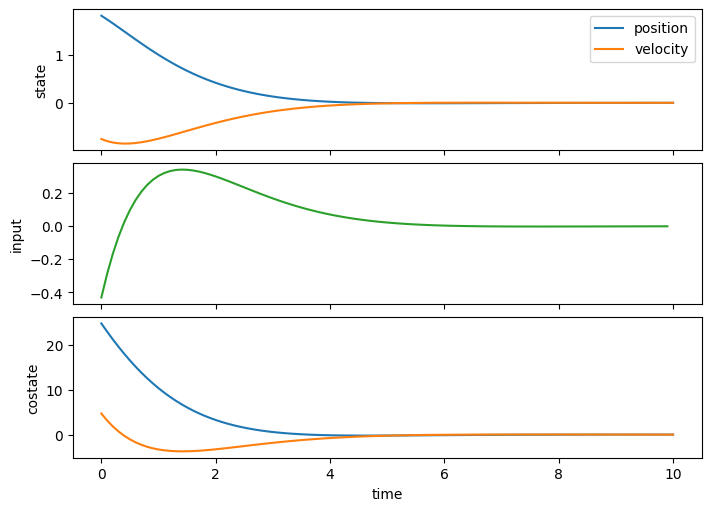

In [4]:
time = jnp.arange(T + 1) * dims.dt
fig, axes = plt.subplots(3, 1, figsize=(7, 5), sharex=True, layout="constrained")
axes[0].plot(time, Xs, label=["position", "velocity"])
axes[0].legend()
axes[1].plot(time[:-1], Us, c="C2")
axes[2].plot(time, lambdas)
for ax, label in zip(axes, ["state", "input", "costate"]):
    ax.set_ylabel(label)
axes[-1].set_xlabel("time");

## Checking optimality

At the optimum, the gradients of the Lagrangian with respect to $x$, $u$ and $\lambda$ are zero.
`diffilqrax.lqr.kkt` returns these residuals. They should be at the level of float64
round-off.

In [5]:
dLdX, dLdU, dLdLambda = kkt(params, Xs, Us, lambdas)
for name, r in [("dL/dx", dLdX), ("dL/du", dLdU), ("dL/dλ", dLdLambda)]:
    print(f"max|{name}| = {jnp.max(jnp.abs(r)):.2e}")

max|dL/dx| = 0.00e+00
max|dL/du| = 1.89e-15
max|dL/dλ| = 2.78e-17


The parallel solver uses an associative scan instead of the sequential recursion. It returns the
same solution:

In [6]:
Xp, Up, _ = solve_plqr(params)
print(f"max|Xs - Xp| = {jnp.max(jnp.abs(Xs - Xp)):.2e},  max|Us - Up| = {jnp.max(jnp.abs(Us - Up)):.2e}")

max|Xs - Xp| = 4.44e-16,  max|Us - Up| = 1.28e-15


## How to adapt

- **Your own linear system:** replace `A`, `B` and `dims`. If the system is time-varying, build
  arrays of shape `(T, n, n)` and `(T, n, m)` directly instead of tiling.
- **Costs:** a larger `R` relative to `Q` gives gentler inputs and slower convergence.
  `Qf` sets how strongly the final state is pinned. `Q`, `Qf` must be positive semi-definite and
  `R` positive definite.
- **Offsets and cross terms:** use `a` for affine dynamics (for example gravity) and `S` for
  state–input coupling in the cost.
- **Tracking a target:** use the linear terms `q` and `qf`, as shown in the
  [tracking example](lqr_tracking_integrator.ipynb).
- **Long horizons on a GPU:** switch to `solve_plqr`. It has the same inputs and outputs.